# 01 - EDA: Dự đoán sinh viên có nguy cơ bỏ học
FIT4013 - Đề tài 8. Người làm: TV1.

Chạy notebook từ thư mục `notebooks/`. Hình được lưu vào `reports/figures/`.

In [4]:
import sys
sys.path.append("../src")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from data import load_data, TARGET

sns.set_theme(style="whitegrid")
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()

df = load_data()
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 1. Cấu trúc dữ liệu

In [5]:
print("Kích thước:", df.shape)
print("Số giá trị thiếu:", df.isna().sum().sum())
print("Số dòng trùng:", df.duplicated().sum())
print(df.dtypes.value_counts())
df.info()

Kích thước: (4424, 37)
Số giá trị thiếu: 0
Số dòng trùng: 0
int64      29
float64     7
str         1
Name: count, dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   M

## 2. Phân loại cột
Dùng số giá trị khác nhau (`nunique`) để chia cột thành nhị phân, mã định danh và số liên tục.

In [6]:
nu = df.drop(columns=TARGET).nunique().sort_values()
print(nu.to_string())

Daytime/evening attendance                          2
Displaced                                           2
Debtor                                              2
Educational special needs                           2
International                                       2
Scholarship holder                                  2
Gender                                              2
Tuition fees up to date                             2
Marital status                                      6
Application order                                   8
Inflation rate                                      9
Curricular units 2nd sem (without evaluations)     10
GDP                                                10
Unemployment rate                                  10
Curricular units 1st sem (without evaluations)     11
Previous qualification                             17
Course                                             17
Application mode                                   18
Curricular units 2nd sem (cr

In [7]:
# Chốt danh sách cột (kiểm tra lại với bảng nunique ở trên)
BINARY_COLS = [
    "Daytime/evening attendance", "Displaced", "Educational special needs",
    "Debtor", "Tuition fees up to date", "Gender", "Scholarship holder",
    "International",
]
ID_COLS = [
    "Marital status", "Application mode", "Course", "Previous qualification",
    "Nacionality", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation",
]
feature_cols = [c for c in df.columns if c != TARGET]
NUM_COLS = [c for c in feature_cols if c not in BINARY_COLS + ID_COLS]

# Kiểm tra các cột có tồn tại không
missing = [c for c in BINARY_COLS + ID_COLS if c not in df.columns]
print("Cột không tìm thấy:", missing)
print(f"Nhị phân: {len(BINARY_COLS)} | Định danh: {len(ID_COLS)} | Số: {len(NUM_COLS)}")
print("\nCột số:", NUM_COLS)

Cột không tìm thấy: []
Nhị phân: 8 | Định danh: 9 | Số: 19

Cột số: ['Application order', 'Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP']


**Ghi chú cho báo cáo:** các cột mã định danh (Course, Application mode, nghề cha mẹ...) là mã số không có thứ tự, nên không được coi là biến liên tục. Ở Luồng B chúng được One-Hot.

## 3. Phân phối nhãn

          số lượng  tỷ lệ %
Target                     
Graduate      2209     49.9
Dropout       1421     32.1
Enrolled       794     17.9


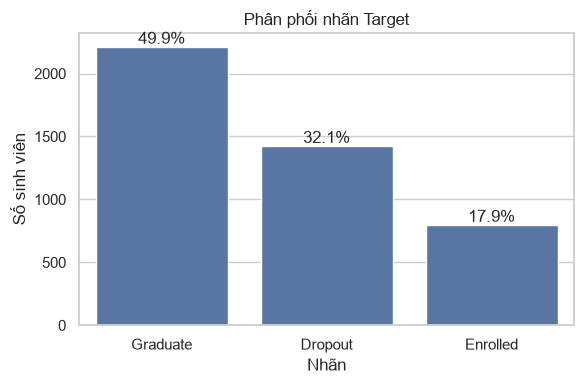

In [8]:
counts = df[TARGET].value_counts()
pct = (counts / len(df) * 100).round(1)
print(pd.DataFrame({"số lượng": counts, "tỷ lệ %": pct}))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x=TARGET, order=counts.index, ax=ax)
for p, v in zip(ax.patches, pct):
    ax.annotate(f"{v}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Phân phối nhãn Target")
ax.set_xlabel("Nhãn"); ax.set_ylabel("Số sinh viên")
save("eda_01_target.png")

Dữ liệu **mất cân bằng nhẹ** (Graduate chiếm gần một nửa, Enrolled chỉ khoảng 18%), vì vậy dùng **F1-macro** làm thang đo chính và chia dữ liệu có `stratify`.

## 4. Biến số: histogram và boxplot

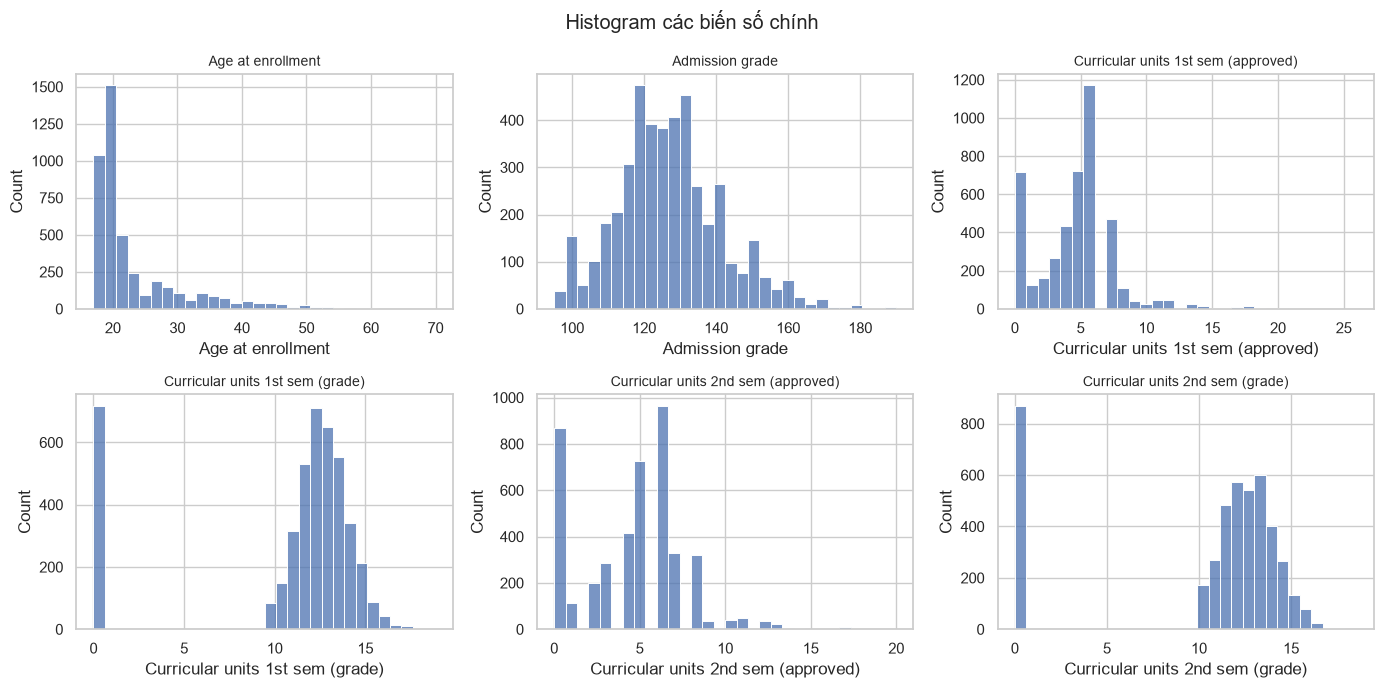

In [9]:
key_num = [
    "Age at enrollment",
    "Admission grade",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
]
key_num = [c for c in key_num if c in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), key_num):
    sns.histplot(df[c], bins=30, ax=ax)
    ax.set_title(c, fontsize=10)
fig.suptitle("Histogram các biến số chính")
save("eda_02_hist.png")

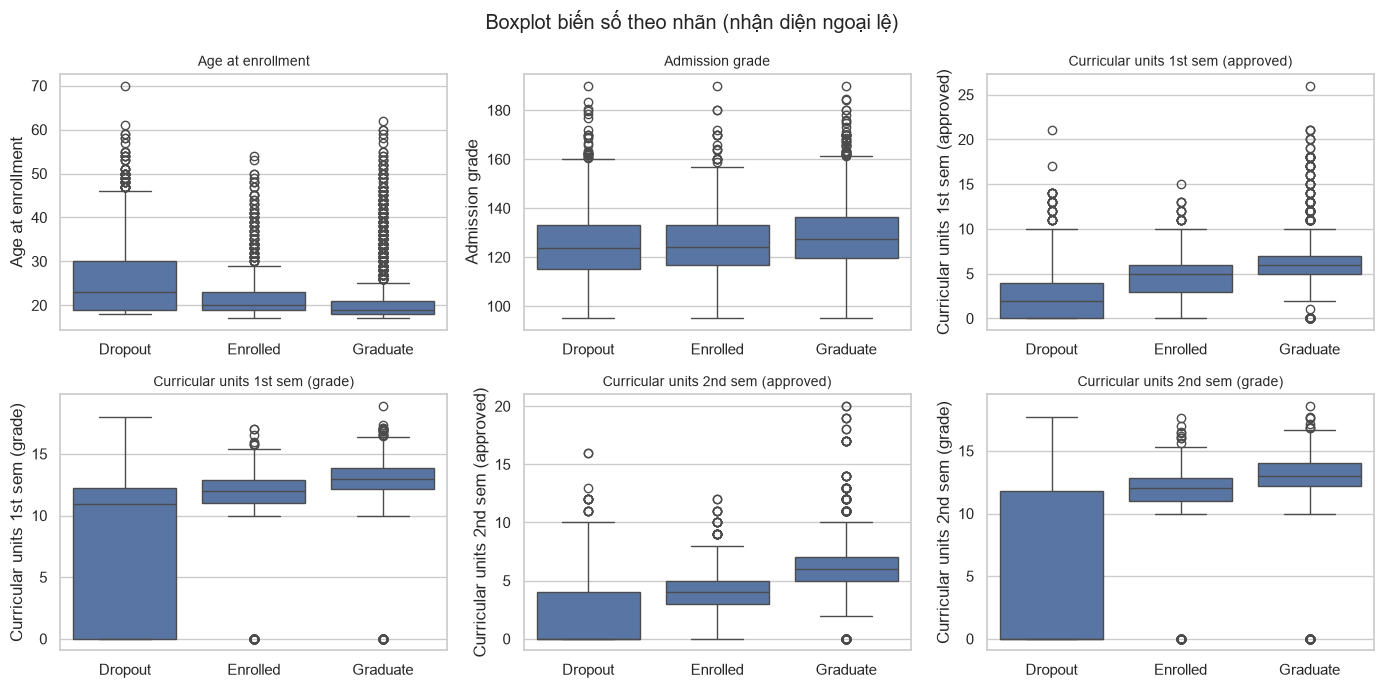

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), key_num):
    sns.boxplot(data=df, x=TARGET, y=c, ax=ax,
                order=["Dropout", "Enrolled", "Graduate"])
    ax.set_title(c, fontsize=10); ax.set_xlabel("")
fig.suptitle("Boxplot biến số theo nhãn (nhận diện ngoại lệ)")
save("eda_03_boxplot.png")

In [11]:
# Thống kê ngoại lệ theo quy tắc IQR
rows = []
for c in NUM_COLS:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    rows.append((c, n_out, round(n_out / len(df) * 100, 1)))
pd.DataFrame(rows, columns=["cột", "số ngoại lệ", "%"]).sort_values("số ngoại lệ", ascending=False)

,cột,số ngoại lệ,%
14,Curricular units 2nd sem (grade),877,19.8
8,Curricular units 1st sem (grade),726,16.4
4,Curricular units 1st sem (credited),577,13.0
0,Application order,541,12.2
10,Curricular units 2nd sem (credited),530,12.0
3,Age at enrollment,441,10.0
5,Curricular units 1st sem (enrolled),424,9.6
11,Curricular units 2nd sem (enrolled),369,8.3
9,Curricular units 1st sem (without evaluations),294,6.6
15,Curricular units 2nd sem (without evaluations),282,6.4


## 5. Biến tài chính và nhân khẩu theo nhãn

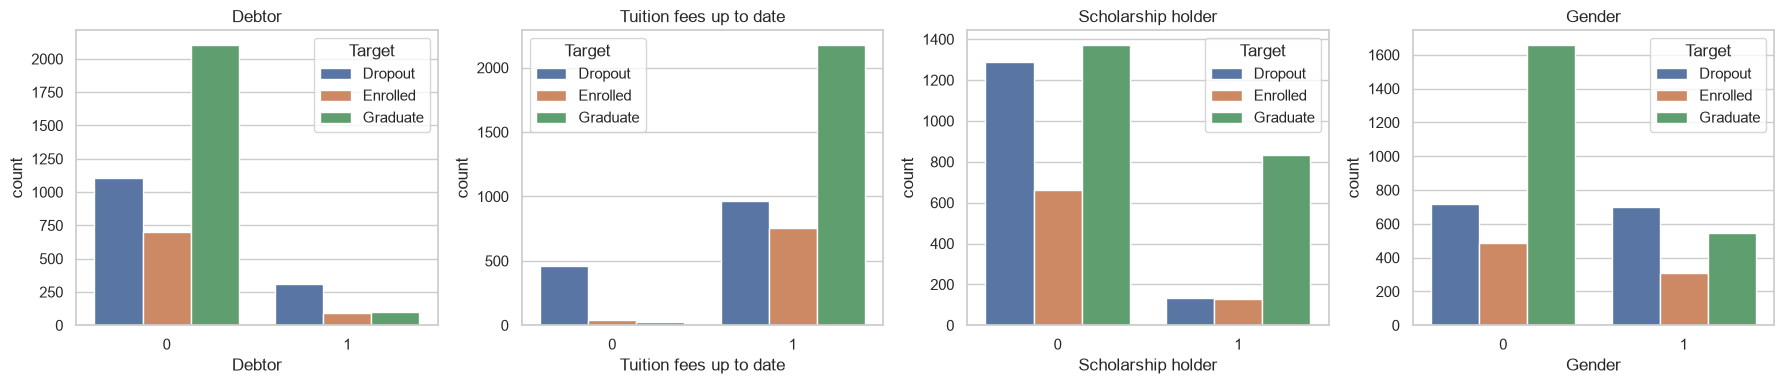

In [12]:
cols = ["Debtor", "Tuition fees up to date", "Scholarship holder", "Gender"]
cols = [c for c in cols if c in df.columns]
fig, axes = plt.subplots(1, len(cols), figsize=(4.5 * len(cols), 4))
for ax, c in zip(axes, cols):
    sns.countplot(data=df, x=c, hue=TARGET, hue_order=["Dropout", "Enrolled", "Graduate"], ax=ax)
    ax.set_title(c)
save("eda_04_financial.png")

In [13]:
# Tỷ lệ Dropout theo từng nhóm (dễ đọc hơn đếm thô)
for c in cols:
    print(f"\n{c}")
    print((pd.crosstab(df[c], df[TARGET], normalize="index") * 100).round(1))


Debtor
Target  Dropout  Enrolled  Graduate
Debtor                             
0          28.3      18.0      53.8
1          62.0      17.9      20.1

Tuition fees up to date
Target                   Dropout  Enrolled  Graduate
Tuition fees up to date                             
0                           86.6       8.0       5.5
1                           24.7      19.3      56.0

Scholarship holder
Target              Dropout  Enrolled  Graduate
Scholarship holder                             
0                      38.7      20.0      41.3
1                      12.2      11.8      76.0

Gender
Target  Dropout  Enrolled  Graduate
Gender                             
0          25.1      17.0      57.9
1          45.1      19.7      35.2


## 6. Heatmap tương quan

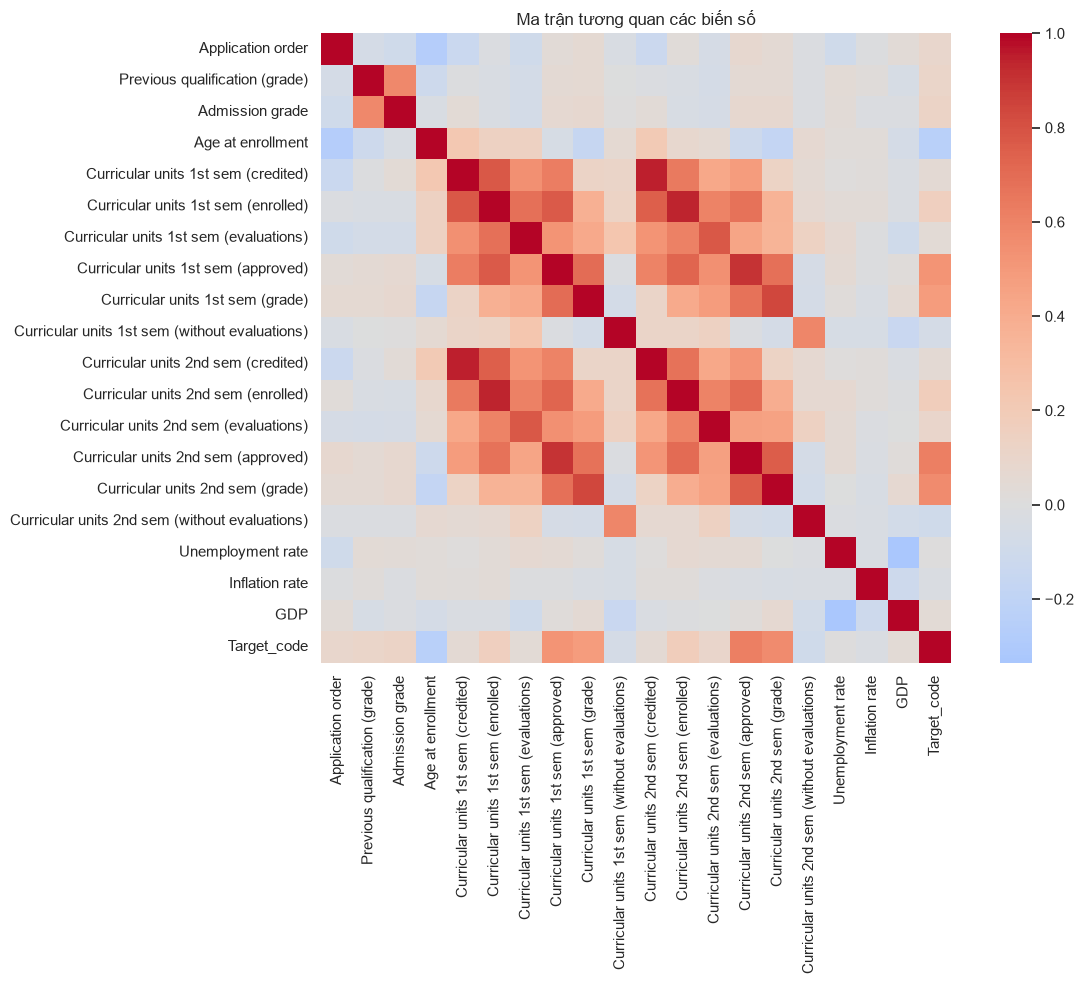

Curricular units 2nd sem (approved)               0.624
Curricular units 2nd sem (grade)                  0.567
Curricular units 1st sem (approved)               0.529
Curricular units 1st sem (grade)                  0.485
Age at enrollment                                -0.243
Curricular units 2nd sem (enrolled)               0.176
Curricular units 1st sem (enrolled)               0.156
Admission grade                                   0.121
Previous qualification (grade)                    0.104
Curricular units 2nd sem (without evaluations)   -0.094
Name: Target_code, dtype: float64


In [14]:
tmp = df.copy()
tmp["Target_code"] = tmp[TARGET].map({"Dropout": 0, "Enrolled": 1, "Graduate": 2})
corr_cols = NUM_COLS + ["Target_code"]
corr = tmp[corr_cols].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True)
plt.title("Ma trận tương quan các biến số")
save("eda_05_corr.png")

print(corr["Target_code"].drop("Target_code").sort_values(key=abs, ascending=False).head(10).round(3))

Các cặp biến học kỳ 1 và học kỳ 2 (đăng ký, đạt, điểm) tương quan mạnh với nhau. Điều này gợi ý tạo đặc trưng tỷ lệ ở Luồng B.

## 7. Dữ liệu bất thường

In [15]:
g1 = "Curricular units 1st sem (grade)"
e1 = "Curricular units 1st sem (enrolled)"
e2 = "Curricular units 2nd sem (enrolled)"

print("Điểm HK1 = 0:", (df[g1] == 0).sum())
print("Số môn đăng ký HK1 = 0:", (df[e1] == 0).sum())
print("Số môn đăng ký HK2 = 0:", (df[e2] == 0).sum())

zero_grade = df[df[g1] == 0]
print("\nPhân bố nhãn của nhóm điểm HK1 = 0:")
print((zero_grade[TARGET].value_counts(normalize=True) * 100).round(1))

zero_enr = df[df[e1] == 0]
print("\nPhân bố nhãn của nhóm 0 môn đăng ký HK1:")
print((zero_enr[TARGET].value_counts(normalize=True) * 100).round(1))

Điểm HK1 = 0: 718
Số môn đăng ký HK1 = 0: 180
Số môn đăng ký HK2 = 0: 180

Phân bố nhãn của nhóm điểm HK1 = 0:
Target
Dropout     79.4
Graduate    10.7
Enrolled     9.9
Name: proportion, dtype: float64

Phân bố nhãn của nhóm 0 môn đăng ký HK1:
Target
Dropout     42.8
Graduate    41.7
Enrolled    15.6
Name: proportion, dtype: float64


**Nhận xét cho báo cáo:** điểm bằng 0 thường là sinh viên không đăng ký hoặc không thi, không phải lỗi nhập liệu. Nhóm này nghiêng mạnh về Dropout nên là tín hiệu hữu ích, **giữ nguyên, không xóa hay điền bù**. Khi tính tỷ lệ ở Luồng B, các dòng 0 môn đăng ký cho kết quả 0 (chia cho 0 trả về 0).

## 8. Tóm tắt kết quả EDA (điền số thật vào báo cáo)

In [16]:
print(f"Kích thước: {df.shape}, thiếu: {df.isna().sum().sum()}, trùng: {df.duplicated().sum()}")
print("Nhãn:", pct.to_dict())
print("Danh sách hình đã lưu:")
for f in sorted(FIG.glob("eda_*.png")):
    print(" -", f.name)

Kích thước: (4424, 37), thiếu: 0, trùng: 0
Nhãn: {'Graduate': 49.9, 'Dropout': 32.1, 'Enrolled': 17.9}
Danh sách hình đã lưu:
 - eda_01_target.png
 - eda_02_hist.png
 - eda_03_boxplot.png
 - eda_04_financial.png
 - eda_05_corr.png
